# Week 12 demo: random DAPI cutout

The `demo/` folder holds two DAPI image volumes, `dapi1.tif` and `dapi2.tif`, downloaded with
[`cloud-volume`](https://github.com/seung-lab/cloud-volume). Each is stored in cloud-volume's
axis order **(x, y, z, channel) = (4096, 4096, 3, 1)**: a 4096 × 4096 field of view, 3 z-slices, 1 channel.

This notebook:
1. picks one of the two volumes at random,
2. picks a random **(1024, 1024, 1)** region (x, y, z) inside it,
3. saves that region as `demo/dapi_cutout.tif`, ready to open in the Cellpose GUI.

Re-run the notebook to get a different cutout. Set `SEED` to an integer to get the same cutout every time.

> `dapi_cutout.tif` is a generated file and is listed in `.gitignore`. Do not commit it.

In [1]:
from pathlib import Path

import numpy as np
import tifffile
import matplotlib.pyplot as plt

In [2]:
DEMO_DIR = Path("./")
SOURCES = [DEMO_DIR / "dapi1.tif", DEMO_DIR / "dapi2.tif"]
OUTPUT = DEMO_DIR / "dapi_cutout.tif"

CUTOUT_SIZE = (1024, 1024, 1)   # (x, y, z)
SEED = None                     # e.g. 42 for a reproducible cutout

rng = np.random.default_rng(SEED)

## 1. Pick a volume at random

In [3]:
source = SOURCES[rng.integers(len(SOURCES))]
volume = tifffile.imread(source)          # shape (x, y, z, channel)
volume = volume[..., 0]                   # single channel -> (x, y, z)

print("Source:", source.name)
print("Volume shape (x, y, z):", volume.shape, volume.dtype)

Source: dapi1.tif
Volume shape (x, y, z): (4096, 4096, 3) uint16


## 2. Pick a random (1024, 1024, 1) region

For each axis, the start index can be anything from 0 up to `axis length - cutout size`,
so the region always fits inside the volume.

In [4]:
starts = [int(rng.integers(0, n - s + 1)) for n, s in zip(volume.shape, CUTOUT_SIZE)]
x0, y0, z0 = starts
sx, sy, sz = CUTOUT_SIZE

cutout = volume[x0:x0 + sx, y0:y0 + sy, z0:z0 + sz]

print(f"Region: x {x0}:{x0 + sx}, y {y0}:{y0 + sy}, z {z0}:{z0 + sz}")
print("Cutout shape (x, y, z):", cutout.shape)

Region: x 465:1489, y 730:1754, z 0:1
Cutout shape (x, y, z): (1024, 1024, 1)


## 3. Save as a TIFF

Image viewers and Cellpose expect a 2D image in **(row, column) = (y, x)** order, so we drop the
length-1 z axis and transpose before saving. The saved image is 1024 × 1024 pixels, uint16.

In [5]:
image = cutout[:, :, 0].T                # (x, y) -> (y, x)
tifffile.imwrite(OUTPUT, image)

print("Saved", OUTPUT, image.shape, image.dtype)

Saved dapi_cutout.tif (1024, 1024) uint16


## 4. Quick look

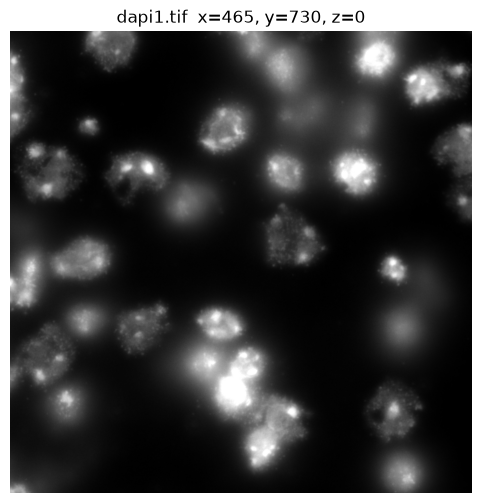

In [6]:
lo, hi = np.percentile(image, [1, 99.5])   # contrast stretch for display only

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray", vmin=lo, vmax=hi)
plt.title(f"{source.name}  x={x0}, y={y0}, z={z0}")
plt.axis("off")
plt.show()